In [ ]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
plt.rcParams.update({
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.top': True,
    'ytick.right': True,
    
    'font.size': 24,
    'axes.labelsize': 28,
    'legend.fontsize': 15,
    'font.family': 'Times New Roman',
    'mathtext.fontset': 'cm',
    'lines.linewidth': 3,
    'lines.markersize': 8,
    'figure.figsize': [4,4]
})

import numpy as np
from scipy.optimize import curve_fit
import glob
import os

In [ ]:
def array_from(file_path: str, col_num: list):
    with open(file_path, 'r', encoding='utf-8') as file:
        lines = file.readlines()
    lines = [line.strip().split('\t') for line in lines]
    
    ret = []
    for j in col_num:
        ps = [float(line[j]) for line in lines]
        ret.append(ps)
    
    return np.array(ret)

def AMR(deg, R0, Ram, alpha):
    rad = np.radians(deg) + alpha
    return R0 + Ram * np.cos(rad)**2

def AMR_a(deg, R0, Ram, alpha, a):
    return AMR(deg, R0, Ram, alpha) + a * deg

fit_deg_limit = [0, 360]
fit_deg = np.linspace(*fit_deg_limit, 100)

In [ ]:
# AMR
# data = [deg, voltage(V), deg, NaN]
################################
folder = r'C:\Users\user\OneDrive\Desktop\교토 대학원\6. Experiment\4. Project\3. Cryo\2026-05-25-AMR\sample-A'
file_name = '*'
extracted_rows = [0,1]
AMR_I = 1e-4 # A
################################

..\file\Cryoleft\7-1_AZO53Ni10\7-1_22_AZO53Ni10\250710_AMR\7-1_22_AZO53Ni10_4_1__3_2_AMR_K_18h45_0mA_900Oeave3times

IR0[V], IRam[V]
0.02228762513247448 8.443256314881294e-08 5.837901359848198e-05 9.376447781730915e-08
a   : 0.0094407 ± 0.00088029 (rad)
R0[Ω], Ram[Ω]
222.8762513247448 0.0008443256314881294 0.5837901359848198 0.0009376447781730915


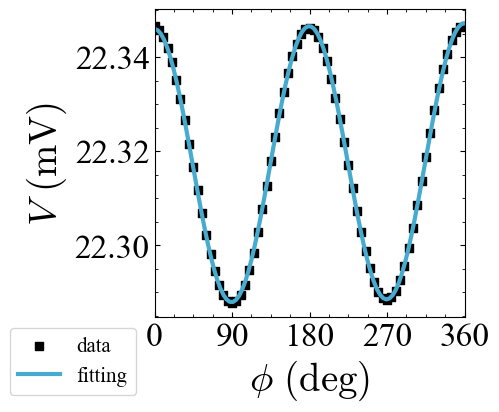

In [ ]:


files = glob.glob(os.path.join(folder, file_name))
for file in files:
    print(file)

# dt = ave of [deg, vol(V)]
dt = array_from(files[0], extracted_rows)

# plot
popt, pcov = curve_fit(AMR_a, dt[0], dt[1], p0=[0,0,0,0])

fig = plt.figure()
fig_1 = fig.add_subplot(111)

fig_1.scatter(dt[0], dt[1] * 10**3, marker='s', color='k', label='data', s=40)
fig_1.plot(fit_deg, AMR_a(fit_deg, *popt) * 10**3, color=cm.GnBu(0.65), label='fitting')

fig_1.set_xlim(fit_deg_limit)
fig_1.set_xlabel(r'$\phi\ \mathrm{(deg)}$')
fig_1.set_ylabel(r'$V\ \mathrm{(mV)}$')
fig_1.legend(loc='upper left', bbox_to_anchor=(-0.5, 0), ncol=1, fontsize=15)
fig_1.set_xticks([0,90,180,270,360])
fig_1.minorticks_on()

print()
print('IR0[V], IRam[V]')
print(popt[0], np.sqrt(pcov[0][0]), popt[1], np.sqrt(pcov[1][1]))
print('a   :', '{:.5g}'.format(popt[2]), '±', '{:.5g}'.format(np.sqrt(pcov[2][2])), '(rad)')
print('R0[Ω], Ram[Ω]')
print(popt[0]/AMR_I, np.sqrt(pcov[0][0])/AMR_I, popt[1]/AMR_I, np.sqrt(pcov[1][1])/AMR_I)
plt.show()